# 1. Exploratory data analysis

**FEE308 Data Mining, group NonRefundable.** Author: Mikhail Savushkin.

Question: can we predict, at the moment a booking is made, whether it will be cancelled?

This notebook looks at the data before any modelling. Every section ends with what it means for preprocessing,
so the choices in `src/preprocessing.py` and the model notebooks can be traced back to something we saw here.

**Rule for this notebook.** Facts about how the data was recorded (size, missing values, broken rows) are checked on
the full dataset. Anything that relates a column to the target is looked at on the **training split only**. If we
picked features by looking at the test set, the final test score would no longer be an honest estimate.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent
sys.path.append(str(ROOT / "src"))
from preprocessing import LEAKAGE_COLS, TARGET, UNUSED_COLS, clean, load_raw, split_train_test

FIG_DIR = ROOT / "report" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
STAY, CANCEL = "#4C72B0", "#DD8452"


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 0. Overview

In [2]:
raw = load_raw()
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

119,390 rows x 32 columns


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:
feature_types = {
    "numeric": ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children",
                "babies", "previous_cancellations", "previous_bookings_not_canceled", "booking_changes",
                "days_in_waiting_list", "adr", "required_car_parking_spaces", "total_of_special_requests"],
    "categorical": ["meal", "country", "market_segment", "distribution_channel", "reserved_room_type",
                    "assigned_room_type", "deposit_type", "agent", "company", "customer_type",
                    "reservation_status"],
    "binary": ["hotel", "is_repeated_guest"],
    "date": ["arrival_date_year", "arrival_date_month", "arrival_date_week_number",
             "arrival_date_day_of_month", "reservation_status_date"],
}
assert sum(len(v) for v in feature_types.values()) + 1 == raw.shape[1]

pd.DataFrame({
    "columns": {k: len(v) for k, v in feature_types.items()},
    "examples": {k: ", ".join(v[:4]) for k, v in feature_types.items()},
})

,columns,examples
numeric,13,"lead_time, stays_in_weekend_nights, stays_in_w..."
categorical,11,"meal, country, market_segment, distribution_ch..."
binary,2,"hotel, is_repeated_guest"
date,5,"arrival_date_year, arrival_date_month, arrival..."


`agent` and `company` are stored as numbers, but they are anonymised IDs, so we treat them as categories.

## 1. Target balance

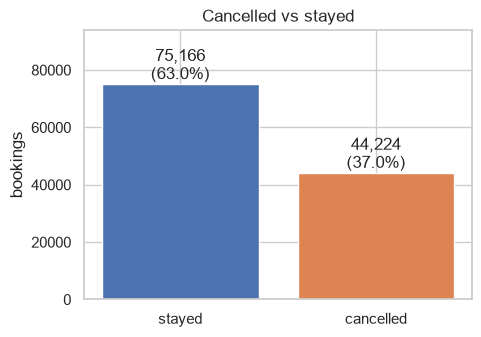

In [4]:
counts = raw[TARGET].value_counts().rename({0: "stayed", 1: "cancelled"})

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(counts.index, counts.values, color=[STAY, CANCEL])
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}\n({v / len(raw):.1%})", ha="center", va="bottom")
ax.set_ylim(0, counts.max() * 1.25)
ax.set_ylabel("bookings")
ax.set_title("Cancelled vs stayed")
save(fig, "target_balance")

37% of bookings are cancelled. The classes are moderately imbalanced, which means:

- the split and the cross-validation folds must be **stratified**, so every fold keeps the 37/63 ratio;
- accuracy alone is misleading: always predicting "stayed" already gives 63%;
- we use **PR-AUC** as the main metric. Its no-skill level equals the share of the positive class (0.37), so our
  target of 0.70 is clearly above chance.

## 2. Data quality (full dataset)

In [5]:
missing = raw.isna().sum()
missing = missing[missing > 0].to_frame("missing")
missing["share"] = (missing["missing"] / len(raw)).map("{:.2%}".format)
missing

,missing,share
children,4,0.00%
country,488,0.41%
agent,16340,13.69%
company,112593,94.31%


- `company` is missing for 94% of bookings and is only an ID, so we drop it.
- A missing `agent` most likely means the booking was made directly, not through a travel agent, so it becomes its
  own category instead of being imputed.
- `country` (0.4%) gets an "unknown" category, `children` (4 rows) is filled with the median.

In [6]:
guests = raw["adults"] + raw["children"].fillna(0) + raw["babies"]
print("bookings with zero guests:", (guests == 0).sum())
print("bookings with negative adr:", (raw["adr"] < 0).sum())
raw["adr"].describe(percentiles=[0.5, 0.99, 0.999]).round(1)

bookings with zero guests: 180
bookings with negative adr: 1


count    119390.0
mean        101.8
std          50.5
min          -6.4
50%          94.6
99%         252.0
99.9%       326.2
max        5400.0
Name: adr, dtype: float64

A booking with no guests or a negative price cannot be real, so these 181 rows are removed as data errors.
The maximum `adr` of 5,400 is far above the 99.9th percentile, but it is a single row, so it has almost no effect on
the scaler and we keep it.

After cleaning we split off the test set (stratified, 20%, `random_state=42`) and **do not look at it again**
until the final evaluation.

In [7]:
df = clean(raw)
print(f"removed {len(raw) - len(df)} rows, {len(df):,} left")

train, test = split_train_test(df)
pd.DataFrame(
    {"rows": [len(train), len(test)], "cancellation rate": [train[TARGET].mean(), test[TARGET].mean()]},
    index=["train", "test"],
).round(4)

removed 181 rows, 119,209 left


,rows,cancellation rate
train,95367,0.3708
test,23842,0.3708


## 3. Leakage: columns that know the answer

A column *leaks* when it is filled in only after we already know whether the guest cancelled. A model trained with
it looks excellent in testing, but it could never be used at booking time. From here on we use `train` only.

In [8]:
pd.crosstab(train["reservation_status"], train[TARGET])

is_canceled,0,1
reservation_status,,
Canceled,0,34390
Check-Out,60008,0
No-Show,0,969


`reservation_status` is just the target written in words: "Canceled" and "No-Show" are always 1, "Check-Out" is
always 0. Dropped.

In [9]:
arrival = pd.to_datetime(
    train["arrival_date_year"].astype(str) + "-" + train["arrival_date_month"] + "-"
    + train["arrival_date_day_of_month"].astype(str),
    format="%Y-%B-%d",
)
days = (pd.to_datetime(train["reservation_status_date"]) - arrival).dt.days
days.groupby(train["reservation_status"]).describe()[["count", "mean", "25%", "50%", "75%"]].round(1)

,count,mean,25%,50%,75%
reservation_status,,,,,
Canceled,34390.0,-88.4,-131.0,-56.0,-19.0
Check-Out,60008.0,3.4,2.0,3.0,4.0
No-Show,969.0,-0.1,0.0,0.0,0.0


`reservation_status_date` is the date of the *last* status change: for cancellations it lies before the arrival
date (the day the booking was cancelled), for stays it is the departure day. It describes the outcome, not the
booking. Dropped.

In [10]:
room_changed = train["assigned_room_type"] != train["reserved_room_type"]
room_changed.groupby(train[TARGET]).mean().rename({0: "stayed", 1: "cancelled"}).map("{:.1%}".format)

is_canceled
stayed       18.7%
cancelled     1.8%
dtype: str

`assigned_room_type` is set at check-in. A different room was given to 18.7% of guests who stayed, but only to
1.8% of cancellations, because a guest who never arrives is rarely moved. Dropped.

### Suspicious columns

The next columns are not obviously post-outcome, but they can be updated after the booking date:

In [11]:
by_target = train.groupby(TARGET)
pd.DataFrame({
    "booking_changes > 0": by_target["booking_changes"].apply(lambda s: (s > 0).mean()),
    "on waiting list": by_target["days_in_waiting_list"].apply(lambda s: (s > 0).mean()),
    "parking space requested": by_target["required_car_parking_spaces"].apply(lambda s: (s > 0).mean()),
}).rename(index={0: "stayed", 1: "cancelled"}).round(3)

,booking_changes > 0,on waiting list,parking space requested
is_canceled,,,
stayed,0.202,0.018,0.098
cancelled,0.063,0.054,0.000


In [12]:
parking = train["required_car_parking_spaces"] > 0
print(f"bookings with a parking space: {parking.sum():,}, cancelled: {train.loc[parking, TARGET].mean():.1%}")

bookings with a parking space: 5,899, cancelled: 0.0%


- Guests who stayed changed their booking much more often. Part of these changes probably happen during the stay
  (e.g. extending it), which only guests who arrive can do.
- **Not a single** booking with a parking space was cancelled. This looks like a field filled in at arrival.
- `country` is discussed in section 4.

We cannot prove leakage from the data alone, so we keep these columns in the main models and train a second version
**without** them. If the scores drop a lot, the difference is reported as possible leakage.

## 4. What drives cancellations (train only)

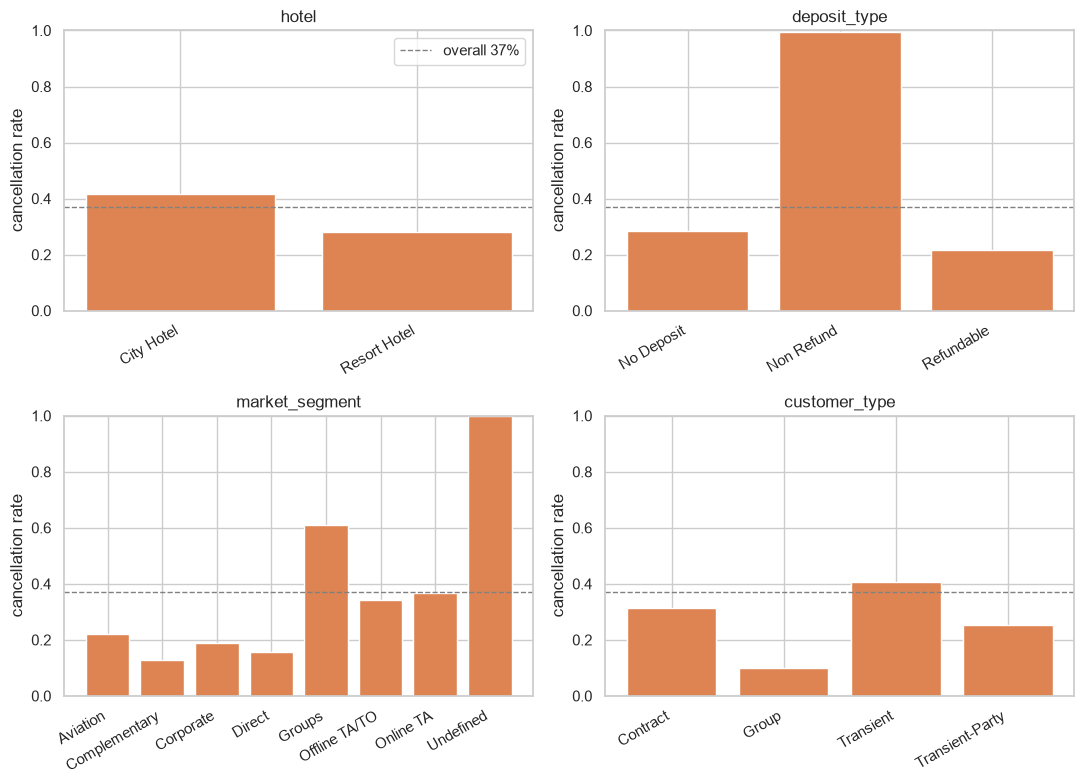

In [13]:
base_rate = train[TARGET].mean()


def rate_plot(data, col, ax, order=None, top=None, rotate=0):
    stats = data.groupby(col, observed=True)[TARGET].agg(rate="mean", n="size")
    if top:
        stats = stats.nlargest(top, "n")
    if order is not None:
        stats = stats.reindex([o for o in order if o in stats.index])
    ax.bar(stats.index.astype(str), stats["rate"], color=CANCEL)
    ax.axhline(base_rate, color="grey", ls="--", lw=1, label=f"overall {base_rate:.0%}")
    ax.set_ylim(0, 1)
    ax.set_title(col)
    ax.set_ylabel("cancellation rate")
    ax.set_xlabel("")
    if rotate:
        plt.setp(ax.get_xticklabels(), rotation=rotate, ha="right")
    return stats


fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.flat, ["hotel", "deposit_type", "market_segment", "customer_type"]):
    rate_plot(train, col, ax, rotate=30)
axes[0, 0].legend()
fig.tight_layout()
save(fig, "rates_categorical")

In [14]:
train.groupby("deposit_type")[TARGET].agg(rate="mean", n="size").round(3)

,rate,n
deposit_type,,
No Deposit,0.284,83569
Non Refund,0.993,11668
Refundable,0.215,130


- The city hotel has a clearly higher cancellation rate than the resort hotel, so we will also evaluate them
  separately.
- **Non Refund** deposits are cancelled about 99% of the time. It sounds backwards and is a known oddity of this
  dataset; a likely explanation is that many of these are blocks of rooms reserved by tour operators and released
  later. Deposit type is known at booking time, so the column stays, and it is probably the strongest feature.
- The `Groups` market segment cancels the most (61%); direct and corporate bookings cancel the least. Customer type
  `Group` behaves very differently (10%), so the two columns carry different information.

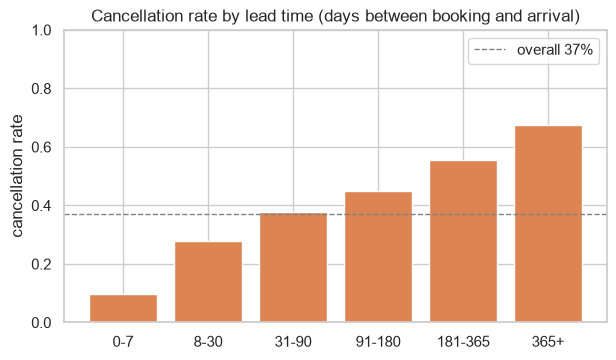

In [15]:
bins = [-1, 7, 30, 90, 180, 365, train["lead_time"].max()]
labels = ["0-7", "8-30", "31-90", "91-180", "181-365", "365+"]
lead = train.assign(lead_time_days=pd.cut(train["lead_time"], bins=bins, labels=labels))

fig, ax = plt.subplots(figsize=(7, 3.8))
rate_plot(lead, "lead_time_days", ax, order=labels)
ax.set_title("Cancellation rate by lead time (days between booking and arrival)")
ax.legend()
save(fig, "rate_lead_time")

The earlier the booking, the more likely it is cancelled: from about 10% for last-week bookings to more than half
for bookings made over six months ahead. The effect is monotonic, so even a linear model can use it.

,months,bookings
arrival_date_year,,
2015,6,17530
2016,12,45354
2017,8,32483


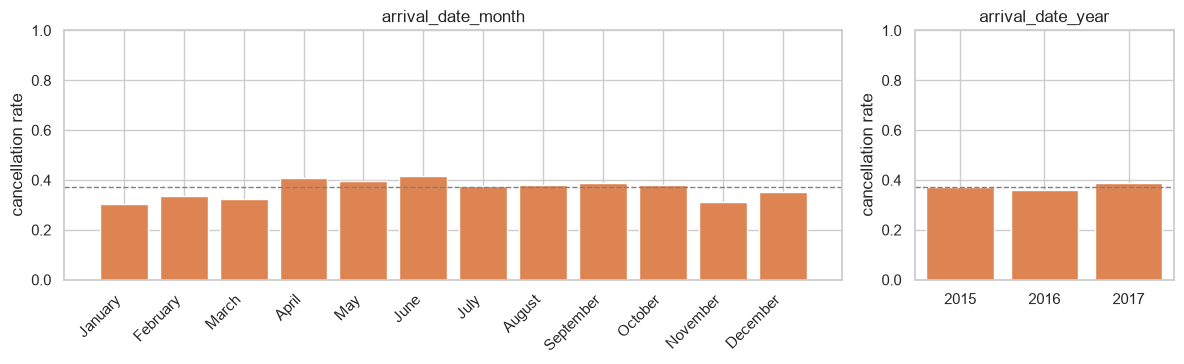

In [16]:
months = ["January", "February", "March", "April", "May", "June", "July", "August", "September",
          "October", "November", "December"]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [3, 1]})
rate_plot(train, "arrival_date_month", axes[0], order=months, rotate=45)
rate_plot(train, "arrival_date_year", axes[1])
fig.tight_layout()
save(fig, "rates_time")

train.groupby("arrival_date_year").agg(months=("arrival_date_month", "nunique"), bookings=(TARGET, "size"))

There is a seasonal pattern: about 31-32% in January, March and November, up to 40-42% from April to June. The
arrival month is kept as a one-hot feature. The year is dropped: the rate barely changes between years (36-39%),
2015 only covers July to December and 2017 only January to August, and a model
used for future bookings would only ever see a year it was not trained on. Week number repeats the month, and day of
the month has no plausible link to cancelling, so both are dropped as well.

,rate,n
country,,
PRT,0.567,38851
GBR,0.203,9656
FRA,0.184,8344
ESP,0.252,6798
DEU,0.166,5843
ITA,0.354,2990
IRL,0.252,2681
BEL,0.205,1884
BRA,0.375,1767


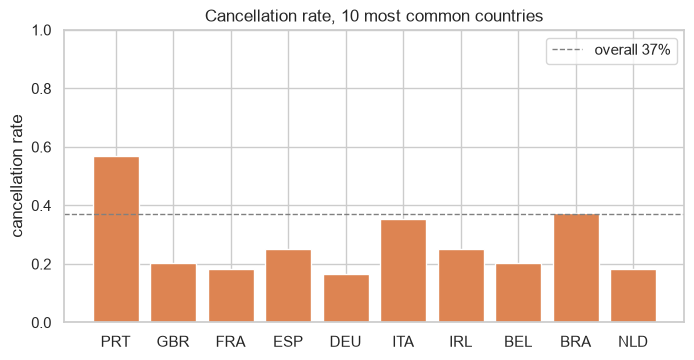

In [17]:
fig, ax = plt.subplots(figsize=(8, 3.8))
countries = rate_plot(train, "country", ax, top=10)
ax.set_title("Cancellation rate, 10 most common countries")
ax.legend()
save(fig, "rate_country")
countries.round(3)

In [18]:
for col in ["country", "agent"]:
    share = train[col].value_counts(normalize=True, dropna=False)
    frequent = share[share >= 0.01]
    print(f"{col}: {train[col].nunique()} values, {len(frequent)} with at least 1% of bookings, "
          f"covering {frequent.sum():.1%} of train")

country: 170 values, 14 with at least 1% of bookings, covering 89.7% of train
agent: 322 values, 13 with at least 1% of bookings, covering 75.5% of train


Portugal is both the most common country and has a cancellation rate around 57%, almost three times the other big
countries. A likely reason is that the booking system fills in the guest's country properly only at check-in, so a
booking that is cancelled often keeps the default value. That would be leakage, so `country` joins the
"with vs without" check from section 3. Country is also a sensitive attribute (nationality), so we will compare
model performance for the largest country groups.

Countries and agents with less than 1% of bookings are grouped into "Other". The cut-off is learned inside the
pipeline on each training fold, not here.

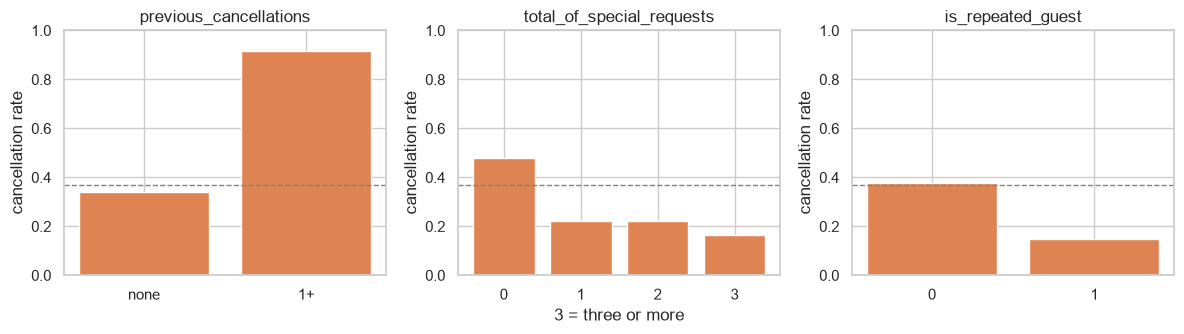

In [19]:
extra = train.assign(
    previous_cancellations=train["previous_cancellations"].clip(upper=1).map({0: "none", 1: "1+"}),
    total_of_special_requests=train["total_of_special_requests"].clip(upper=3),
)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
rate_plot(extra, "previous_cancellations", axes[0], order=["none", "1+"])
rate_plot(extra, "total_of_special_requests", axes[1])
rate_plot(extra, "is_repeated_guest", axes[2])
axes[1].set_xlabel("3 = three or more")
fig.tight_layout()
save(fig, "rates_history")

Guests who cancelled before tend to cancel again, guests with special requests cancel less (they plan to come),
and repeated guests cancel less. All three are known at booking time and stay in the model.

## 5. Duplicate bookings

The dataset has no booking ID, so we can check how many rows are exact copies of each other.

In [20]:
model_cols = [c for c in df.columns if c not in LEAKAGE_COLS + UNUSED_COLS + [TARGET]]
all_cols = [c for c in df.columns if c not in LEAKAGE_COLS + [TARGET]]

print(f"exact duplicate rows in the raw data: {raw.duplicated().sum():,} ({raw.duplicated().mean():.1%})")


def row_keys(data, cols):
    return pd.util.hash_pandas_object(data[cols].astype(str), index=False)


for name, cols in [("all recorded columns", all_cols), ("model features", model_cols)]:
    twin = row_keys(test, cols).isin(set(row_keys(train, cols)))
    print(f"test rows with an identical row in train ({name}): {twin.mean():.1%}")

dup = train.duplicated(subset=model_cols, keep=False)
print(f"cancellation rate in train: duplicated rows {train.loc[dup, TARGET].mean():.1%}, "
      f"unique rows {train.loc[~dup, TARGET].mean():.1%}")

exact duplicate rows in the raw data: 31,994 (26.8%)
test rows with an identical row in train (all recorded columns): 33.3%


test rows with an identical row in train (model features): 33.8%
cancellation rate in train: duplicated rows 57.9%, unique rows 26.5%


About a quarter of all rows are exact copies, most likely group bookings entered as several identical
reservations. They are real bookings, so we do not delete them. But with a random split, at least a third of the
test rows have an identical twin in the training data (only the features are compared above, never test targets).
A k-NN model can simply find that twin, and a deep tree can memorise it, so the test score may be too optimistic.

To measure this, we repeat cross-validation with a **grouped split** (`StratifiedGroupKFold`), where identical
rows always fall in the same fold, and report the difference next to the main results.

## 6. Summary: what goes into preprocessing

| Finding | Decision |
|---|---|
| 37% cancelled, moderate imbalance | Stratified split and folds; PR-AUC and F1 (cancelled) as main metrics; `class_weight` tuned |
| `reservation_status`, `reservation_status_date`, `assigned_room_type` set after the outcome | Dropped (leakage) |
| `company` 94% missing, anonymised ID | Dropped |
| 180 bookings with no guests, 1 negative `adr` | Removed as data errors |
| `children` 4 missing, `country` 0.4% missing, `agent` missing = direct booking | Median; "unknown"; "none" |
| Hundreds of rare countries and agents | Values under 1% of bookings grouped into "Other", learned inside the pipeline |
| Clear seasonality by month, nothing useful in year / week / day | Keep month (one-hot); drop year, week number, day of month |
| `booking_changes`, `days_in_waiting_list`, `required_car_parking_spaces`, `country` may be filled in after booking | Main model keeps them; extra run without them, difference reported |
| Big difference between the two hotels and between countries | Report performance per hotel and for the largest countries |
| About a third of test rows have a twin in train | Extra evaluation with a grouped split |
| Numeric columns on very different scales (`lead_time` up to 700, `adr` up to 5,400) | `StandardScaler`, needed for k-NN and logistic regression |